# 04d Extreme Frequency ScenarioMIP vs CDRMIP comparison

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats, plotting
from cdrmip_extremes.load_processed import load_extremes, load_land_ocean_masks
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
ssp_ext_data = load_extremes(
    PROC_DIR, 'ScenarioMIP',
    outputs=['exceedances_matching_median_multimodel', 'branch_differences_matching_median_multimodel','agreement_matching'],
    # model_order=CDR_MODELS,
)
cdr_ext_data = load_extremes(
    PROC_DIR, 'CDRMIP',
    outputs=['exceedances_median_multimodel', 'branch_differences_median_multimodel','agreement'],
    model_order=CDR_MODELS,
)

  sort_models: no order defined for ['multi_model_median'], appending at end
  sort_models: no order defined for ['multi_model_median'], appending at end


In [5]:
ssp_exceedances_all = ssp_ext_data['exceedances_matching_median_multimodel']
ssp_differences_all = ssp_ext_data['branch_differences_matching_median_multimodel']
ssp_agreement_all = ssp_ext_data['agreement_matching']

cdr_exceedances = cdr_ext_data['exceedances_median_multimodel']
cdr_differences = cdr_ext_data['branch_differences_median_multimodel']
cdr_agreement = cdr_ext_data['agreement']

In [6]:
expt = 'ssp534-over'
ssp_differences = {
    model: {
        expt: {
            ext_type: ds for ext_type, ds in ext_type_dt.items()
        } for expt, ext_type_dt in expt_dt.items()
    } for model, expt_dt in ssp_differences_all.items() if model in CDR_MODELS
}
ssp_exceedances = {
    model: {
        expt: {
            ext_type: ds for ext_type, ds in ext_type_dt.items()
        } for expt, ext_type_dt in expt_dt.items()
    } for model, expt_dt in ssp_exceedances_all.items() if model in CDR_MODELS
}

ssp_agreement = {expt:{}}
for ext_type in ['cold','heat']:
    ssp_agreement[expt][ext_type] = extremes.calc_agreement(
        { 
            model:ssp_differences[model][expt][ext_type] for model in ssp_differences.keys()
        }
    )

In [7]:
ssp_differences['multi_model_median'] = {
    expt: {
        ext_type: xr.concat(
            [ssp_differences[model][expt][ext_type] for model in ssp_differences.keys()],
            dim='model',
            compat='override',
            coords='minimal'
        ).median(dim='model') for ext_type in ['heat','cold']
    }
}
ssp_exceedances['multi_model_median'] = {
    expt: {
        ext_type: xr.concat(
            [ssp_differences[model][expt][ext_type] for model in ssp_exceedances.keys()],
            dim='model',
            compat='override',
            coords='minimal'
        ).median(dim='model') for ext_type in ['heat','cold']
    }
}

## Calculate correlation

In [8]:
thresholds = ['sigma1', 'sigma2', 'sigma3']

corr_differences = {}
for model in cdr_differences.keys() & ssp_differences.keys():
    corr_differences[model] = {}
    for ext_type in ['heat', 'cold']:
        cdr_da = cdr_differences[model]['1pctCO2-cdr'][ext_type].sel(gwl=1.5)[thresholds].to_array('threshold')
        ssp_da = ssp_differences[model]['ssp534-over'][ext_type].isel(gwl=0)[thresholds].to_array('threshold')
        corr = xr.corr(cdr_da, ssp_da, dim=['lat', 'lon'])
        corr_differences[model][ext_type] = np.round(corr.values,2)

In [9]:
corr_differences

{'MIROC-ES2L': {'heat': array([0.47, 0.41, 0.39]),
  'cold': array([0.52, 0.55, 0.66])},
 'UKESM1-0-LL': {'heat': array([0.21, 0.32, 0.39]),
  'cold': array([0.17, 0.13, 0.1 ])},
 'CanESM5': {'heat': array([0.14, 0.28, 0.32]),
  'cold': array([ 0.1 ,  0.09, -0.02])},
 'ACCESS-ESM1-5': {'heat': array([0.61, 0.56, 0.37]),
  'cold': array([0.49, 0.47, 0.42])},
 'multi_model_median': {'heat': array([0.5 , 0.55, 0.45]),
  'cold': array([0.33, 0.29, 0.2 ])},
 'CNRM-ESM2-1': {'heat': array([0.46, 0.57, 0.57]),
  'cold': array([0.35, 0.31, 0.3 ])}}

## Plot all thresholds

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S22.jpg


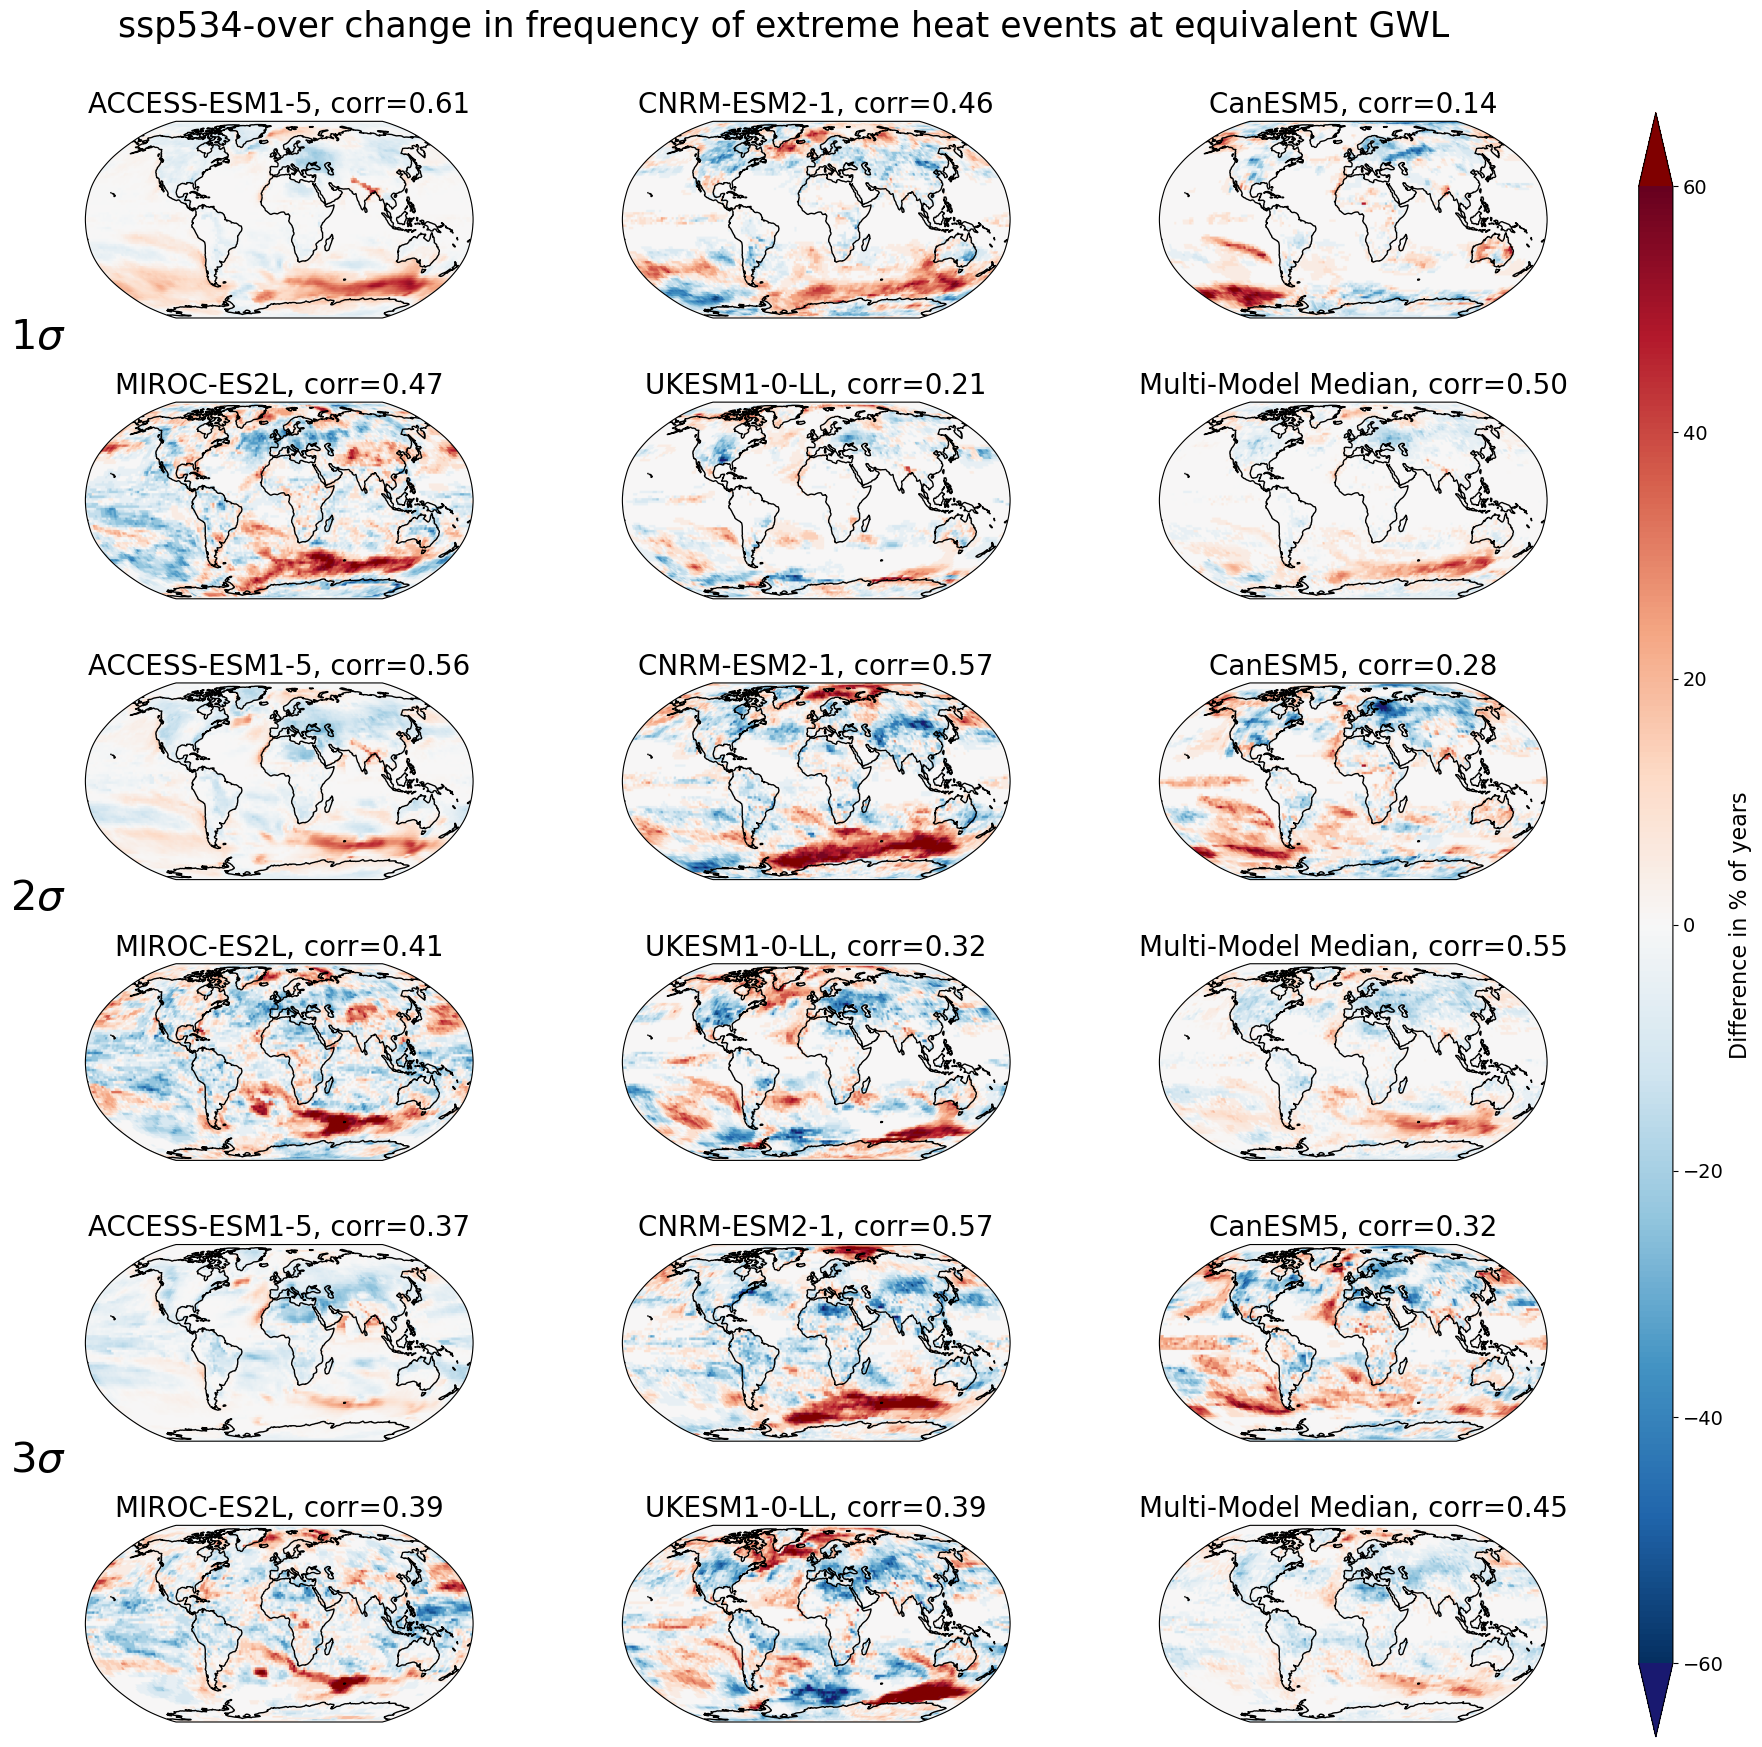

In [10]:
fig = plotting.plot_ext_freq_diff_corr_all_thresholds(
    differences=ssp_differences,
    expt='ssp534-over',
    ext_type='heat',
    gwl=None,
    period='equivalent',
    levels=None,
    # label='(c)',
    title='-1$\sigma$',
    vmin=-60,
    vmax=60,
    exclude_models = (),
    corr_dict=corr_differences,
    n_cols=3,
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S22.jpg'
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S23.jpg


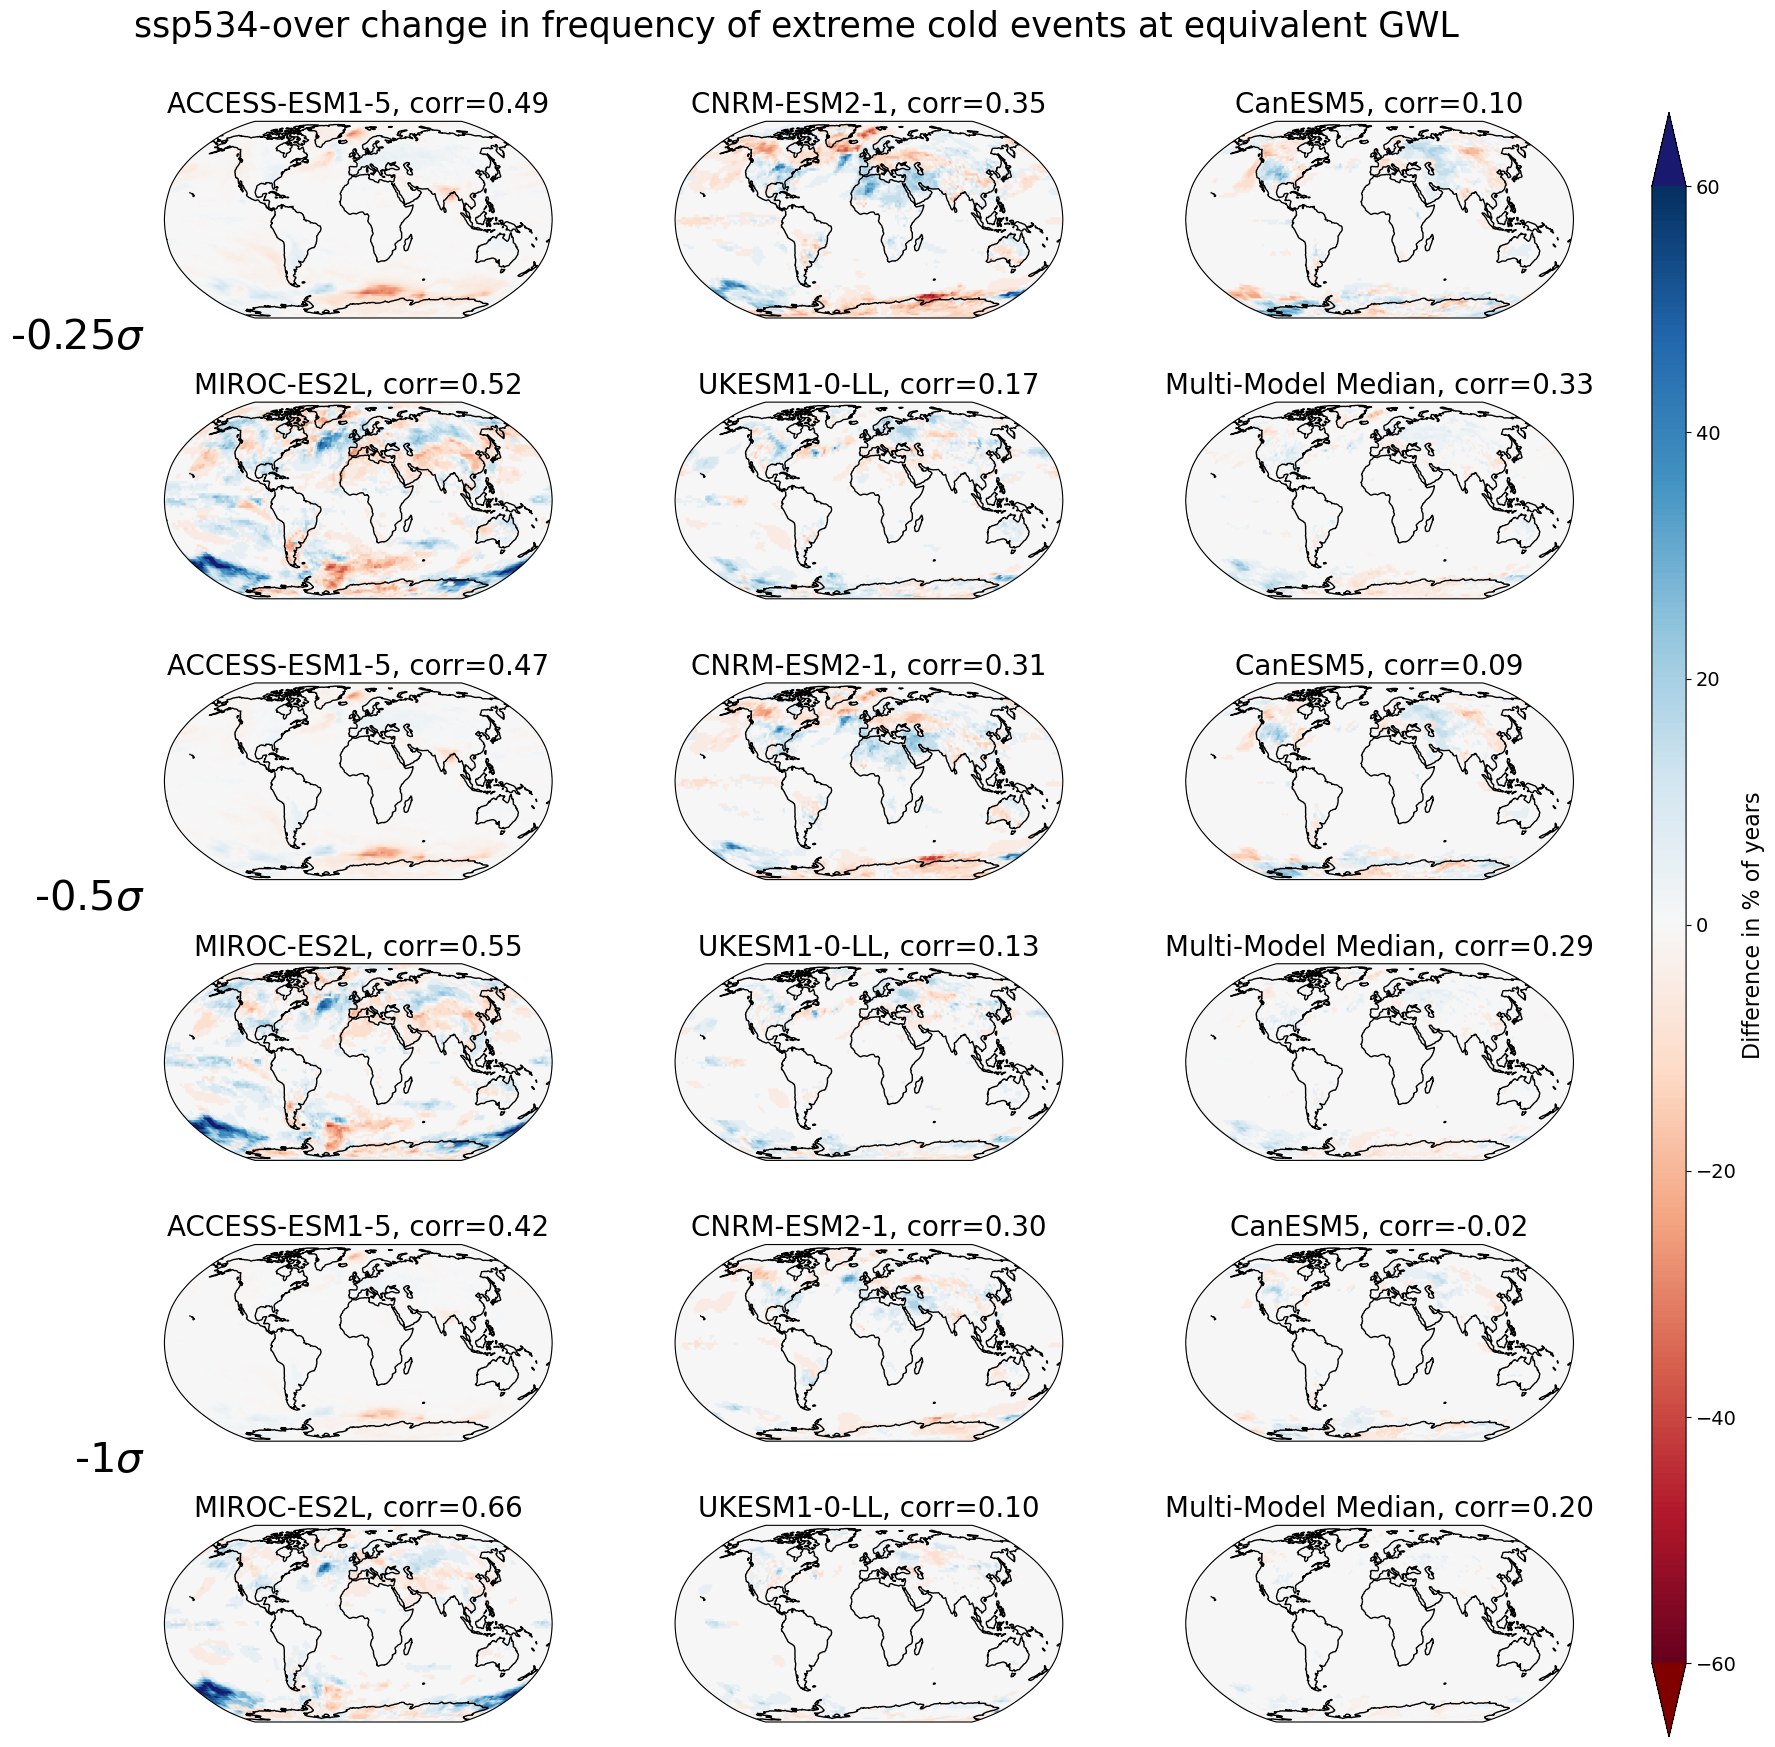

In [11]:
fig = plotting.plot_ext_freq_diff_corr_all_thresholds(
    differences=ssp_differences,
    expt='ssp534-over',
    ext_type='cold',
    gwl=None,
    period='equivalent',
    levels=None,
    title='-1$\sigma$',
    vmin=-60,
    vmax=60,
    exclude_models = (),
    corr_dict=corr_differences,
    n_cols=3,
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S23.jpg'
)